# Sequence recovery at RNA interfaces with and without molecular context

Reproduces the paper figure `sequence_recovery_interfaces` (written to `paper/figures/` as `.png`, `.svg` and `.pdf`).

For every RNA chain in the test structures, RISoTTo designs the residues in contact (< 5 Å) with each binding partner (protein, small molecule, RNA, DNA or ion):
- **without context**: the RNA chain is given alone,
- **with context**: the full complex is given and the sequences of all other chains are known.

The per-interface results are in `data/context_interfaces/{PDBID}.csv` (`context_level` 0 = without context, 2 = with context). They are produced by `test_model_context.py` at the repository root (see `paper/README.md`).

In [1]:
import os
from glob import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

PAPER_DIR = os.path.abspath("")
RESULTS_DIR = os.path.join(PAPER_DIR, "data", "context_interfaces")
FIG_DIR = os.path.join(PAPER_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 10,
    "font.weight": "bold",
    "axes.linewidth": 1.0,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 120,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

In [2]:
df = pd.concat([pd.read_csv(fp) for fp in sorted(glob(os.path.join(RESULTS_DIR, "*.csv")))])

keys = ["protein", "ligand", "rna", "dna", "ion"]
labels = ["protein", "small molecule", "RNA", "DNA", "ion"]
ys_l = [df[(df["context_level"] == 0) & (df["binder_type"] == k)]["recovery_rate"].values for k in keys]
yc_l = [df[(df["context_level"] == 2) & (df["binder_type"] == k)]["recovery_rate"].values for k in keys]

print(f"{df['key'].nunique()} structures")
pd.DataFrame({
    "interface": labels,
    "n": [len(y) for y in yc_l],
    "median without context": [np.median(y) for y in ys_l],
    "median with context": [np.median(y) for y in yc_l],
}).round(3)

142 structures


,interface,n,median without context,median with context
0,protein,22,0.465,0.581
1,small molecule,485,0.429,0.667
2,RNA,214,0.200,0.800
3,DNA,7,0.300,0.833
4,ion,654,0.500,0.667


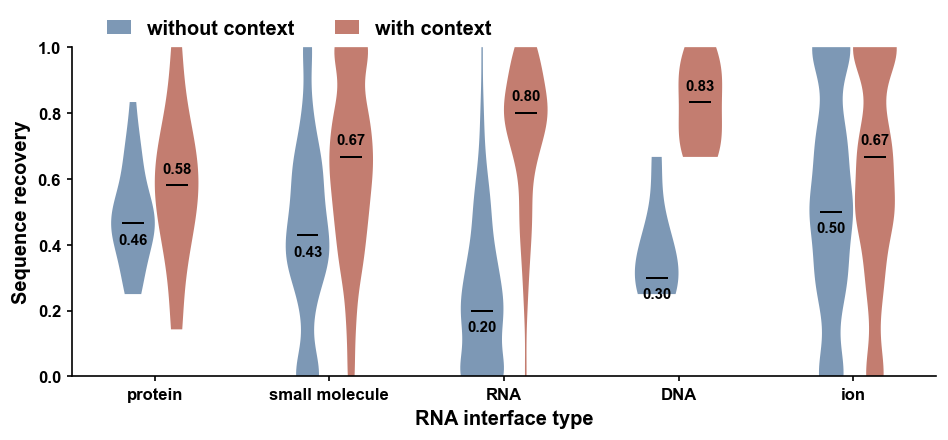

In [3]:
red = "#B55D4C"   # with context
blue = "#5C7FA3"  # without context

x = np.arange(len(keys))
fig, ax = plt.subplots(figsize=(8, 3.8))

# without context
vps = ax.violinplot(ys_l, 2 * x, showextrema=False, showmedians=True, widths=0.5)
for pc in vps["bodies"]:
    pc.set_facecolor(blue)
    pc.set_edgecolor("none")
    pc.set_alpha(0.8)
vps["cmedians"].set_color("black")
vps["cmedians"].set_linewidth(1.2)

# with context
vpc = ax.violinplot(yc_l, 2 * x + 0.5, showextrema=False, showmedians=True, widths=0.5)
for pc in vpc["bodies"]:
    pc.set_facecolor(red)
    pc.set_edgecolor("none")
    pc.set_alpha(0.8)
vpc["cmedians"].set_color("black")
vpc["cmedians"].set_linewidth(1.2)

# median labels
for i in range(len(keys)):
    if len(ys_l[i]) > 0:
        mys = np.median(ys_l[i])
        ax.text(2 * x[i], mys - 0.05, f"{mys:.2f}", ha="center", va="center", fontsize=9)
    if len(yc_l[i]) > 0:
        myc = np.median(yc_l[i])
        ax.text(2 * x[i] + 0.5, myc + 0.05, f"{myc:.2f}", ha="center", va="center", fontsize=9)

ax.set_ylim(0.0, 1.0)
ax.set_xticks(2 * x + 0.25)
ax.set_xticklabels(labels)
ax.set_xlabel("RNA interface type", fontsize=12, fontweight="bold")
ax.set_ylabel("Sequence recovery", fontsize=12, fontweight="bold")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="both", which="major", direction="out", length=3, width=1)

legend_handles = [
    mpatches.Patch(facecolor=blue, label="without context", alpha=0.8),
    mpatches.Patch(facecolor=red, label="with context", alpha=0.8),
]
ax.legend(handles=legend_handles, frameon=False, loc="upper left", bbox_to_anchor=(0.02, 1.14),
          ncol=2, fontsize=12, handlelength=1.2)

plt.tight_layout()
fig_path = os.path.join(FIG_DIR, "sequence_recovery_interfaces")
plt.savefig(fig_path + ".svg")
plt.savefig(fig_path + ".png", dpi=300)
plt.savefig(fig_path + ".pdf", dpi=300)
plt.show()